<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Dataset:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


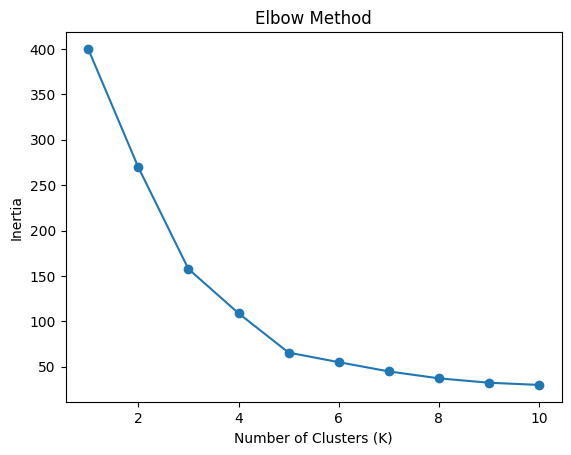


Cluster Centroids:
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]

Silhouette Score: 0.5546571631111091


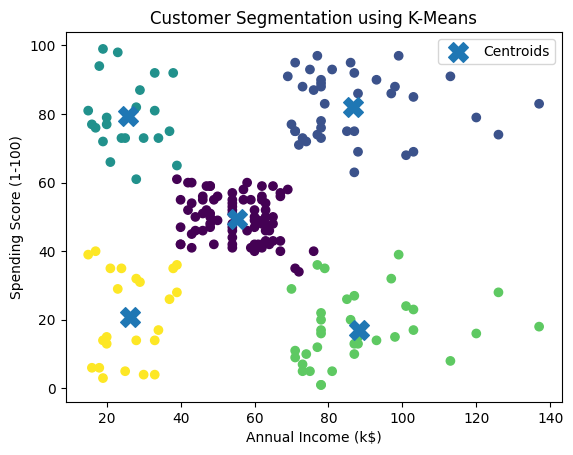

In [ ]:
# K-Means Clustering - Mall Customer Dataset

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# 1. Load Dataset

df = pd.read_csv('/content/drive/MyDrive/ML/Mall_Customers.csv')

print("Dataset:")
print(df.head())


# 2. Select Features

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]


# 3. Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 4. Elbow Method

inertia = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)


# Plot Elbow Graph

plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()


# 5. Apply K-Means with K = 5

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)


# 6. Get Centroids

centroids = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids)

print("\nCluster Centroids:")
print(centroids)


# 7. Silhouette Score

score = silhouette_score(X_scaled, df['Cluster'])

print("\nSilhouette Score:", score)


# 8. Visualize Clusters

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=df['Cluster']
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means')

plt.legend()
plt.show()